# 08 · Model change for the final pipeline: YOLO11m

The best YOLO of notebook 05 (`yolo_s1536_e6`: YOLO11s, 1536 px, 6 epochs) with one change: the **medium** model
(YOLO11m, ~2.2× the parameters of YOLO11s, deeper and wider). Data, input size, epochs, augmentation and seed are those of nb05,
so the difference in the table is the effect of the model alone. Notebook 07 picks the weights up for the ensemble.

**Run:** Kaggle (GPU T4, Internet ON, inputs: competition + notebook 01 output). About 2.5 h.

In [1]:
# environment: Kaggle (data attached as inputs) or Google Colab (data downloaded with the Kaggle API)
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
COMP = "multiple-object-video-detection-hw-2-ucu-ai-2026"
if IN_COLAB:
    # needs the Colab secret KAGGLE_API_TOKEN (Kaggle → Settings → API → Generate New Token)
    from google.colab import userdata, drive
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    drive.mount("/content/drive")                                   # outputs go to Google Drive, so they survive a disconnect
    INPUT, WORK = Path("/content/input"), Path("/content/drive/MyDrive/visdrone_hw2")
    subprocess.run("pip install -q -U kaggle pycocotools", shell=True, check=True)
    if not (INPUT / "comp" / "test_images.csv").exists():
        (INPUT / "comp").mkdir(parents=True, exist_ok=True)
        subprocess.run(f"kaggle competitions download -c {COMP} -p {INPUT / 'comp'} && cd {INPUT / 'comp'} "
                       "&& unzip -q -o '*.zip' && rm -f *.zip", shell=True, check=True)
else:
    INPUT, WORK = Path("/kaggle/input"), Path("/kaggle/working")
    subprocess.run("pip install -q pycocotools", shell=True)
WORK.mkdir(parents=True, exist_ok=True); os.chdir(WORK)
print("Colab" if IN_COLAB else "Kaggle", "| outputs ->", WORK)

Kaggle | outputs -> /kaggle/working


In [2]:
%%writefile vd_utils.py
"""Shared helpers for the VisDrone-VID homework: data loading, COCO evaluation, submission writing."""
import json
from pathlib import Path

import numpy as np
import pandas as pd

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]


def find_data_root(start="/kaggle/input"):
    """Folder that contains train/, val/ and test/ (found by its train/annotations_coco.json)."""
    hits = sorted(Path(start).glob("**/train/annotations_coco.json"))
    if not hits:
        raise FileNotFoundError(f"train/annotations_coco.json not found under {start}: attach the competition data")
    return hits[0].parent.parent


def load_split(root, split):
    """COCO json of one split -> (images, annotations) DataFrames with 0-based `cls` and pixel boxes."""
    root = Path(root)
    coco = json.loads((root / split / "annotations_coco.json").read_text())
    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    if "video" in imgs:
        imgs["clip"] = imgs["video"].astype(str)
    else:
        imgs["clip"] = imgs["file_name"].map(lambda f: Path(f).parent.name)
    imgs["path"] = [_image_path(root, split, f) for f in imgs["file_name"]]

    anns = pd.DataFrame(coco["annotations"])
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index)
    anns["iscrowd"] = anns.get("iscrowd", 0)
    anns["cls"] = anns["category_id"] - 1
    anns = anns.merge(imgs[["image_id", "clip", "width", "height"]], on="image_id")
    return imgs, anns


def _image_path(root, split, file_name):
    for p in (root / split / file_name, root / split / "images" / file_name, root / file_name):
        if p.exists():
            return str(p)
    raise FileNotFoundError(f"image {file_name} not found in {root / split}")


def coco_eval(gt_json, dets, img_ids=None, cat_ids=None, verbose=False):
    """COCO mAP with ignored regions (iscrowd=1) skipped and up to 500 detections per image.

    dets: list of dicts {image_id, category_id (1-based), bbox [x, y, w, h], score}.
    """
    import contextlib, io
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    quiet = contextlib.redirect_stdout(io.StringIO()) if not verbose else contextlib.nullcontext()
    with quiet:
        gt = COCO(str(gt_json))
        if not dets:
            return {k: 0.0 for k in ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]}
        dt = gt.loadRes(dets)
        E = COCOeval(gt, dt, "bbox")
        E.params.maxDets = [1, 100, 500]
        if img_ids is not None:
            E.params.imgIds = list(img_ids)
        if cat_ids is not None:
            E.params.catIds = list(cat_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    out = {k: float(v) for k, v in zip(["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"], s[:6])}
    # per-class AP[.5:.95] from the same evaluation: precision has shape [IoU, recall, class, area, maxDets]
    prec = E.eval["precision"][:, :, :, 0, -1]
    for k, cat in enumerate(E.params.catIds):
        p = prec[:, :, k]
        out[f"AP_{CLASSES[cat - 1]}"] = float(p[p > -1].mean()) if (p > -1).any() else float("nan")
    return out


def write_submission(dets, test_csv, out_path, max_dets=500):
    """dets: dict image_id (str, e.g. clip_001_0000001) -> array N x 6 [cls, score, x, y, w, h] in pixels."""
    test = pd.read_csv(test_csv)
    rows = []
    for image_id in test["image_id"]:
        d = np.asarray(dets.get(image_id, np.zeros((0, 6))), dtype=float).reshape(-1, 6)
        d = d[(d[:, 0] >= 0) & (d[:, 0] < len(CLASSES))]          # e.g. RetinaNet's sigmoid head can output the unused label 0
        d = d[np.argsort(-d[:, 1])][:max_dets]
        rows.append(" ".join(f"{int(c)} {s:.4f} {x:.1f} {y:.1f} {w:.1f} {h:.1f}" for c, s, x, y, w, h in d))
    sub = pd.DataFrame({"image_id": test["image_id"], "PredictionString": rows})
    sub.to_csv(out_path, index=False)
    return sub


def build_yolo(root, out, step=4):
    """Same conversion as notebook 01: every `step`-th train frame, all val frames, ignored regions painted grey (114),
    boxes whose centre lies in an ignored region dropped. Used when notebook 01's output is not available (e.g. Colab)."""
    import shutil
    from PIL import Image
    out = Path(out)
    for split, st in [("train", step), ("val", 1)]:
        imgs, anns = load_split(root, split)
        (out / "images" / split).mkdir(parents=True, exist_ok=True); (out / "labels" / split).mkdir(parents=True, exist_ok=True)
        im = imgs.sort_values(["clip", "frame_id"]); im = im[im.groupby("clip").cumcount() % st == 0]
        by_img = dict(tuple(anns.groupby("image_id")))
        for r in im.itertuples():
            a = by_img.get(r.image_id, anns.iloc[:0])
            ig = a.loc[a.iscrowd == 1, ["x", "y", "w", "h"]].values; ob = a[a.iscrowd == 0]
            name = f"{r.clip}_{Path(r.file_name).stem}"; dst = out / "images" / split / f"{name}.jpg"
            if len(ig):
                px = np.array(Image.open(r.path).convert("RGB"))
                for x, y, w, h in ig.round().astype(int):
                    px[max(y, 0):y + h, max(x, 0):x + w] = 114
                Image.fromarray(px).save(dst, quality=95)
                cx, cy = (ob.x + ob.w / 2).values, (ob.y + ob.h / 2).values
                inside = ((cx[:, None] >= ig[:, 0]) & (cx[:, None] <= ig[:, 0] + ig[:, 2]) &
                          (cy[:, None] >= ig[:, 1]) & (cy[:, None] <= ig[:, 1] + ig[:, 3])).any(1)
                ob = ob[~inside]
            else:
                shutil.copy(r.path, dst)
            lines = [f"{c} {(x + w / 2) / r.width:.6f} {(y + h / 2) / r.height:.6f} {w / r.width:.6f} {h / r.height:.6f}"
                     for c, x, y, w, h in zip(ob.cls, ob.x, ob.y, ob.w, ob.h)]
            (out / "labels" / split / f"{name}.txt").write_text("\n".join(lines))
    (out / "data.yaml").write_text(f"path: {out}\ntrain: images/train\nval: images/val\nnames: {dict(enumerate(CLASSES))}\n")
    return out

Writing vd_utils.py


In [3]:
subprocess.run("pip install -q ultralytics", shell=True, check=True)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import gc, random, time
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from ultralytics import YOLO
import vd_utils as vd

SEED = 42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ROOT = vd.find_data_root(INPUT)
LOCAL = Path("/content/vd_yolo") if IN_COLAB else WORK / "vd_yolo"
hits = sorted(INPUT.glob("**/vd_yolo/data.yaml")) + sorted(LOCAL.parent.glob("vd_yolo/data.yaml"))
YOLO_DIR = hits[0].parent if hits else vd.build_yolo(ROOT, LOCAL, step=4)
DATA_YAML = WORK / "data.yaml"
DATA_YAML.write_text(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames: {dict(enumerate(vd.CLASSES))}\n")
val_imgs, _ = vd.load_split(ROOT, "val")
VAL_GT = ROOT / "val" / "annotations_coco.json"
DEVICE = 0 if torch.cuda.is_available() else "cpu"

def find_file(rel):
    hits = sorted(WORK.glob(rel)) + sorted(INPUT.glob(f"**/{rel}"))
    return hits[0] if hits else None
print("yolo dataset:", YOLO_DIR)

yolo dataset: /kaggle/input/notebooks/yarema1234/notebook0f34d49e70/vd_yolo


## 1. Training (nb05 settings, only the model differs)
`batch=-1` lets Ultralytics pick the largest batch that fits the T4 at 1536 px; gradients are accumulated to the nominal
batch of 64 either way, so the optimisation matches nb05.

In [4]:
NAME = "yolo_m1536_e6"
CFG = dict(imgsz=1536, epochs=6, batch=-1, cos_lr=True, close_mosaic=1, seed=SEED, workers=4 if not IN_COLAB else 2,
           device=DEVICE, project=str(WORK / "yolo_runs"), exist_ok=True, plots=True)
best = find_file(f"yolo_runs/{NAME}/weights/best.pt")
train_min = np.nan
if best is None:
    t0 = time.time()
    YOLO("yolo11m.pt").train(data=str(DATA_YAML), name=NAME, **CFG)
    train_min = (time.time() - t0) / 60
    best = WORK / "yolo_runs" / NAME / "weights" / "best.pt"
    gc.collect(); torch.cuda.empty_cache()
print("weights:", best, "| train min:", round(train_min, 1))

      Params      GFLOPs GPU_mem (GiB)  forward (ms) backward (ms)                   input                  output
    20059176         397         3.523         463.6          1090      (1, 3, 1536, 1536)                    list
    20059176       793.9         6.962         301.5         349.3      (2, 3, 1536, 1536)                    list
    20059176        1588        13.594         284.9         527.4      (4, 3, 1536, 1536)                    list
CUDA out of memory. Tried to allocate 18.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 2.81 MiB is free. Including non-PyTorch memory, this process has 14.56 GiB memory in use. Of the allocated memory 14.31 GiB is allocated by PyTorch, and 53.62 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-mem

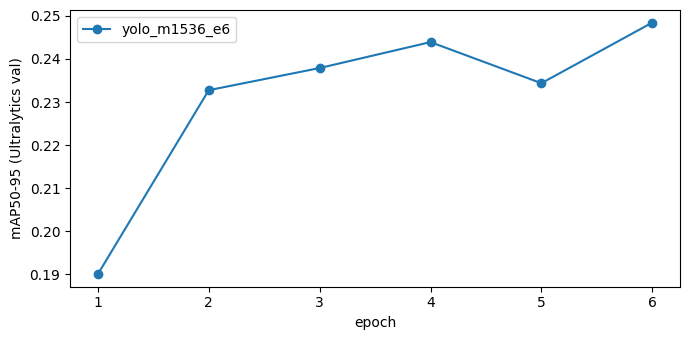

In [5]:
# per-epoch validation mAP logged by Ultralytics (masked val frames; the official metric is in the next cell)
c = pd.read_csv(best.parent.parent / "results.csv"); c.columns = c.columns.str.strip()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(c["epoch"], c["metrics/mAP50-95(B)"], marker="o", label=NAME)
ax.set_xlabel("epoch"); ax.set_ylabel("mAP50-95 (Ultralytics val)"); ax.legend()
plt.tight_layout(); plt.savefig(WORK / "curves_yolo_m.png", dpi=120); plt.show()

## 2. Official validation, compared with YOLO11s (nb05)

In [6]:
def predict(model, paths, imgsz, conf=0.001, iou=0.6, bs=4):
    # {path: array N x 6 [cls, score, x, y, w, h]} in original pixels; small explicit chunks avoid GPU OOM
    out, t0 = {}, time.time()
    for k in range(0, len(paths), bs):
        for r in model.predict(paths[k:k + bs], imgsz=imgsz, conf=conf, iou=iou, max_det=500, verbose=False):
            b = r.boxes; xyxy = b.xyxy.cpu().numpy()
            out[r.path] = np.c_[b.cls.cpu().numpy(), b.conf.cpu().numpy(), xyxy[:, :2], xyxy[:, 2:] - xyxy[:, :2]]
    return out, (time.time() - t0) / len(paths) * 1000

def to_coco(preds, imgs):
    pid = dict(zip(imgs["path"], imgs["image_id"]))
    return [{"image_id": int(pid[p]), "category_id": int(c) + 1, "bbox": [float(x), float(y), float(w), float(h)], "score": float(s)}
            for p, d in preds.items() for c, s, x, y, w, h in d]

model = YOLO(best)
vp, ms = predict(model, val_imgs["path"].tolist(), imgsz=CFG["imgsz"])
R = pd.DataFrame({NAME: {**vd.coco_eval(VAL_GT, to_coco(vp, val_imgs)), "ms / image (incl. disk)": ms, "train min": train_min}}).T
prev = find_file("results_yolo.csv")                                            # nb05 output, if attached
if prev is not None:
    R = pd.concat([pd.read_csv(prev, index_col=0).loc[["yolo_s1536_e6"]], R])
R.to_csv(WORK / "results_yolo_m.csv")
display(R[["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms / image (incl. disk)", "train min"]].astype(float).round(4))
display(R[[f"AP_{c}" for c in vd.CLASSES]].T.astype(float).round(3))

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms / image (incl. disk),train min
yolo_m1536_e6,0.2254,0.4484,0.2003,0.1244,0.2331,0.3234,184.5497,136.1174


,yolo_m1536_e6
AP_person,0.299
AP_bicycle,0.255
AP_car,0.413
AP_van,0.199
AP_truck,0.275
AP_tricycle,0.227
AP_bus,0.007
AP_motor,0.135


## 3. Test submission (YOLO11m alone)

In [7]:
test = pd.read_csv(ROOT / "test_images.csv"); test["path"] = [str(ROOT / f) for f in test["file_name"]]
tp, _ = predict(model, test["path"].tolist(), imgsz=CFG["imgsz"])
dets = {i: tp.get(p, np.zeros((0, 6))) for i, p in zip(test["image_id"], test["path"])}
vd.write_submission(dets, ROOT / "test_images.csv", WORK / "submission_yolo_m.csv")
print("written submission_yolo_m.csv")

written submission_yolo_m.csv
